## Cell 1 — Cài đặt thư viện (chỉ cần chạy 1 lần)

In [ ]:
!pip install timm einops pyyaml tqdm matplotlib scipy -q
print('Cài xong thư viện phụ')

Cài xong thư viện phụ


## Cell 2 — Mount Google Drive & Thiết lập đường dẫn

In [ ]:
import sys
import os
from pathlib import Path

# ============================================================
# THAY ĐỔI 2 ĐƯỜNG DẪN NÀY CHO PHÙ HỢP VỚI MÁY / COLAB CỦA BẠN
# ============================================================
DRIVE_ROOT   = Path('/content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES')  # Thư mục SOURCES trên Drive
MODEL_DIR    = DRIVE_ROOT / 'model'                            # Thư mục model/
DATA_DIR     = DRIVE_ROOT / 'data' / 'processed'              # Thư mục processed/
CONFIG_PATH  = MODEL_DIR / 'configs' / 'train_config.yaml'    # File cấu hình
# ============================================================

# Mount Drive (bỏ qua nếu đang chạy local)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print('✅ Đã mount Google Drive')
except ImportError:
    print('ℹ️  Không phải Colab — bỏ qua bước mount Drive')

# Thêm thư mục model/ vào Python path để import được src.*
for path in [str(MODEL_DIR), str(MODEL_DIR / 'third_party' / 'MambaVision')]:
    if path not in sys.path:
        sys.path.insert(0, path)

print(f'📁 MODEL_DIR  : {MODEL_DIR}')
print(f'📁 DATA_DIR   : {DATA_DIR}')
print(f'📄 CONFIG     : {CONFIG_PATH}')
assert MODEL_DIR.exists(), f'Không tìm thấy thư mục model: {MODEL_DIR}'
assert CONFIG_PATH.exists(), f'Không tìm thấy config: {CONFIG_PATH}'

Mounted at /content/drive
✅ Đã mount Google Drive
📁 MODEL_DIR  : /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/model
📁 DATA_DIR   : /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/data/processed
📄 CONFIG     : /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/model/configs/train_config.yaml


## Cell 3 — Đọc cấu hình (Config)

In [ ]:
import yaml

with open(CONFIG_PATH, 'r', encoding='utf-8') as f:
    config = yaml.safe_load(f)

import shutil, pandas as pd
from pathlib import Path

df = pd.read_csv(DATA_DIR / 'slices.csv')

# Kiểm tra rò rỉ: bệnh nhân không được nằm ở nhiều split
n_leak = (df.groupby('patient_id')['split'].nunique() > 1).sum()
print("Số bệnh nhân nằm ở nhiều split:", n_leak)   # phải bằng 0

# Chọn 30 bệnh nhân cho chạy thử
pids = []
for sp, n in [('train', 20), ('val', 5), ('test', 5)]:
    ids = df[df['split'] == sp]['patient_id'].drop_duplicates()
    pids += list(ids.sample(min(n, len(ids)), random_state=0))

# Copy sang đĩa local của Colab để đọc nhanh (bỏ nghẽn I/O Drive)
dst = Path('/content/data_debug')
(dst / 'volumes').mkdir(parents=True, exist_ok=True)
for p in pids:
    for suf in ('img', 'votes'):
        f = dst / 'volumes' / f'{p}_{suf}.npy'
        if not f.exists():
            shutil.copy(DATA_DIR / 'volumes' / f'{p}_{suf}.npy', f)
df[df['patient_id'].isin(pids)].to_csv(dst / 'slices.csv', index=False)

# Ghi đè đường dẫn: dữ liệu trỏ về bản local, checkpoint vẫn lưu lên Drive
config['DATA']['processed_dir']  = str(dst)
config['DATA']['slices_csv']     = str(dst / 'slices.csv')
config['SAVE']['checkpoint_dir'] = str(MODEL_DIR / 'checkpoints')

print('=== CẤU HÌNH HIỆN TẠI ===')
print(yaml.dump(config, allow_unicode=True, default_flow_style=False))

Số bệnh nhân nằm ở nhiều split: 0
=== CẤU HÌNH HIỆN TẠI ===
DATA:
  augmentation: true
  context_slices: 1
  image_size: 256
  limit_test_samples: 800
  limit_train_samples: 8000
  limit_val_samples: 800
  num_workers: 2
  pin_memory: true
  positive_votes_threshold: 2
  processed_dir: /content/data_debug
  slices_csv: /content/data_debug/slices.csv
MODEL:
  backbone: mamba_vision_T
  decoder_activation: GELU
  decoder_channels:
  - 320
  - 160
  - 80
  - 32
  in_channels: 3
  num_classes: 1
  pretrained: true
  use_batchnorm: true
SAVE:
  checkpoint_dir: /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/model/checkpoints
  enabled: false
  experiment_name: mamba_unet_baseline
  log_interval: 10
  save_best_only: true
SEED: 42
TRAIN:
  batch_size: 8
  early_stopping_patience: 1000
  epochs: 10
  focal_alpha: 0.25
  focal_gamma: 2.0
  learning_rate: 0.0001
  loss_function: DiceBCELoss
  optimizer: AdamW
  scheduler: CosineAnnealingLR
  scheduler_params:
    T_m

## Cell 4 — Thiết lập môi trường (Seed, Device)

In [ ]:
import torch
from src.utils import set_seed, count_parameters

# Khóa random seed để kết quả tái lập được
SEED = config.get('SEED', 42)
set_seed(SEED)

# Xác định thiết bị tính toán
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'🖥️  Thiết bị: {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'   GPU: {torch.cuda.get_device_name(0)}')
    print(f'   VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

[Seed] Đã khóa random seed = 42
🖥️  Thiết bị: cuda
   GPU: Tesla T4
   VRAM: 15.6 GB


## Cell 5 — Tạo Dataset & DataLoader

In [ ]:
from src.dataset import LIDCDataset, get_dataloader
from src.utils  import get_train_transforms, get_val_transforms

# Cau hinh DataLoader
dl_config = {
    'csv_path':       config['DATA']['slices_csv'],
    'processed_dir':  config['DATA']['processed_dir'],
    'batch_size':     config['TRAIN']['batch_size'],
    'num_workers':    config['DATA'].get('num_workers', 2),
    'pin_memory':     config['DATA'].get('pin_memory', True),
    'vote_threshold': config['DATA'].get('positive_votes_threshold', 2),
    'image_size':     config['DATA'].get('image_size', 256),
    'limit_train_samples': config['DATA'].get('limit_train_samples', None),
    'limit_val_samples':   config['DATA'].get('limit_val_samples', None),
    'limit_test_samples':  config['DATA'].get('limit_test_samples', None),
}

# Transforms
train_transform = get_train_transforms(config) if config['DATA'].get('augmentation', True) else None
val_transform   = get_val_transforms(config)

# Tao DataLoader
train_loader = get_dataloader(dl_config, split='train', transform=train_transform)
val_loader   = get_dataloader(dl_config, split='val',   transform=val_transform)
test_loader  = get_dataloader(dl_config, split='test',  transform=val_transform)

print(f'Train batches : {len(train_loader)}')
print(f'Val batches   : {len(val_loader)}')
print(f'Test batches  : {len(test_loader)}')

# Kiem tra shape cua 1 batch
imgs, masks = next(iter(train_loader))
print(f'\nImage batch shape : {imgs.shape}')
print(f'Mask  batch shape : {masks.shape}')
print(f'Ti le pixel duong trong batch: {masks.mean():.4f}')


Train batches : 1000
Val batches   : 100
Test batches  : 100

Image batch shape : torch.Size([8, 3, 256, 256])
Mask  batch shape : torch.Size([8, 1, 256, 256])
Ti le pixel duong trong batch: 0.0006


## Cell 6 — Khởi tạo Model

In [ ]:
from src.models import MambaUNet, build_model

# Khởi tạo model từ config
model = build_model(config)

# Đếm số tham số
count_parameters(model)

# Kiểm tra nhanh: đưa 1 batch giả vào xem output shape
model.eval()
with torch.no_grad():
    fake_input = torch.randn(2, 3, 256, 256).to(DEVICE)
    fake_output = model(fake_input)
    print(f'\n✅ Smoke test thành công!')
    print(f'   Input shape  : {fake_input.shape}')
    print(f'   Output shape : {fake_output.shape}  (kỳ vọng: 2, 1, 256, 256)')

100%|██████████| 364M/364M [00:02<00:00, 133MB/s]


[MambaUNet] Khởi tạo thành công: backbone=mamba_vision_T, pretrained=True
[MambaUNet] Thiết bị: cuda
[Model] Tổng số tham số huấn luyện: 38,211,441

✅ Smoke test thành công!
   Input shape  : torch.Size([2, 3, 256, 256])
   Output shape : torch.Size([2, 1, 256, 256])  (kỳ vọng: 2, 1, 256, 256)


## Cell 7 — Khởi tạo Loss, Optimizer, Scheduler

In [ ]:
from src.utils import build_loss, EarlyStopping

# --- Loss function (đọc tên từ config) ---
criterion = build_loss(config['TRAIN']['loss_function'], config['TRAIN'])
print(f'✅ Loss function  : {criterion.__class__.__name__}')

# --- Optimizer ---
lr           = config['TRAIN']['learning_rate']
weight_decay = config['TRAIN'].get('weight_decay', 0.01)
opt_name     = config['TRAIN'].get('optimizer', 'AdamW')

enc_params = list(model.encoder.parameters())
enc_ids = {id(p) for p in enc_params}
dec_params = [p for p in model.parameters() if id(p) not in enc_ids]
param_groups = [
    {"params": enc_params, "lr": lr},        # encoder pretrained: LR nhỏ
    {"params": dec_params, "lr": lr * 10},   # decoder khởi tạo ngẫu nhiên: LR lớn hơn
]

if opt_name == 'AdamW':
    optimizer = torch.optim.AdamW(param_groups, weight_decay=weight_decay)
elif opt_name == 'SGD':
    optimizer = torch.optim.SGD(param_groups, momentum=0.9, weight_decay=weight_decay)
else:
    raise ValueError(f'Optimizer không được hỗ trợ: {opt_name}')
print(f'✅ Optimizer      : {optimizer.__class__.__name__}  (lr={lr})')

# --- Learning Rate Scheduler ---
sched_name = config['TRAIN'].get('scheduler', 'CosineAnnealingLR')
sched_params = config['TRAIN'].get('scheduler_params', {})

if sched_name == 'CosineAnnealingLR':
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=sched_params.get('T_max', config['TRAIN']['epochs']),
        eta_min=sched_params.get('eta_min', 1e-6)
    )
elif sched_name == 'StepLR':
    scheduler = torch.optim.lr_scheduler.StepLR(
        optimizer,
        step_size=sched_params.get('step_size', 30),
        gamma=sched_params.get('gamma', 0.1)
    )
else:
    scheduler = None
print(f'✅ LR Scheduler   : {sched_name}')

# --- Early Stopping ---
early_stopping = EarlyStopping(patience=config['TRAIN'].get('early_stopping_patience', 15))
print(f'✅ Early Stopping : patience={early_stopping.patience}')

✅ Loss function  : DiceBCELoss
✅ Optimizer      : AdamW  (lr=0.0001)
✅ LR Scheduler   : CosineAnnealingLR
✅ Early Stopping : patience=1000


## Cell 8 — Hàm Train & Validate 1 Epoch

In [ ]:
from tqdm.notebook import tqdm
from src.utils import MetricTracker, dice_score, iou_score

def train_one_epoch(model, loader, criterion, optimizer, device, log_interval=10):
    """Huấn luyện 1 epoch, trả về loss trung bình."""
    model.train()
    tracker = MetricTracker()
    total_loss = 0.0

    pbar = tqdm(loader, desc='  [Train]', leave=False)
    for batch_idx, (images, masks) in enumerate(pbar):
        images = images.to(device, non_blocking=True)
        masks  = masks.to(device, non_blocking=True)

        # Forward
        optimizer.zero_grad()
        preds = model(images)        # (B, 1, H, W) — đã qua Sigmoid
        loss  = criterion(preds, masks)

        # Backward
        loss.backward()
        optimizer.step()

        # Cập nhật metrics
        total_loss += loss.item()
        tracker.update(preds.detach(), masks.detach())

        # Hiển thị log
        if (batch_idx + 1) % log_interval == 0:
            pbar.set_postfix({'loss': f'{loss.item():.4f}'})

    avg_loss = total_loss / len(loader)
    avg_metrics = tracker.mean()
    return avg_loss, avg_metrics


@torch.no_grad()
def validate(model, loader, criterion, device):
    """Đánh giá trên tập validation, trả về loss và metrics."""
    model.eval()
    tracker = MetricTracker()
    total_loss = 0.0

    pbar = tqdm(loader, desc='  [Val]  ', leave=False)
    for images, masks in pbar:
        images = images.to(device, non_blocking=True)
        masks  = masks.to(device, non_blocking=True)

        preds = model(images)
        loss  = criterion(preds, masks)

        total_loss += loss.item()
        tracker.update(preds, masks)

    avg_loss = total_loss / len(loader)
    avg_metrics = tracker.mean()
    return avg_loss, avg_metrics

print('✅ Đã định nghĩa train_one_epoch() và validate()')

✅ Đã định nghĩa train_one_epoch() và validate()


In [ ]:
import time, torch
model.train(); t = time.time()
for i, (x, y) in zip(range(10), train_loader):
    x, y = x.to(DEVICE), y.to(DEVICE)
    optimizer.zero_grad(); criterion(model(x), y).backward(); optimizer.step()
torch.cuda.synchronize()
print("giây/bước:", (time.time() - t) / 10)

giây/bước: 1.5445980072021483


## Cell 9 — Vòng Lặp Huấn Luyện Chính

In [ ]:
from src.utils import save_checkpoint

NUM_EPOCHS  = config['TRAIN']['epochs']
LOG_INTERVAL = config['SAVE'].get('log_interval', 10)

# Lưu lịch sử để vẽ đồ thị sau
history = {
    'train_loss': [], 'val_loss': [],
    'train_dice': [], 'val_dice': [],
    'val_iou':    [], 'lr': [],
}

print(f'🚀 Bắt đầu huấn luyện: {NUM_EPOCHS} epoch\n')

for epoch in range(1, NUM_EPOCHS + 1):
    print(f'Epoch [{epoch:03d}/{NUM_EPOCHS}]')

    # --- Train ---
    train_loss, train_metrics = train_one_epoch(
        model, train_loader, criterion, optimizer, DEVICE, LOG_INTERVAL
    )

    # --- Validate ---
    val_loss, val_metrics = validate(model, val_loader, criterion, DEVICE)

    # --- Cập nhật Scheduler ---
    current_lr = optimizer.param_groups[0]['lr']
    if scheduler is not None:
        scheduler.step()

    # --- Ghi lịch sử ---
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_dice'].append(train_metrics.get('dice', 0))
    history['val_dice'].append(val_metrics.get('dice', 0))
    history['val_iou'].append(val_metrics.get('iou', 0))
    history['lr'].append(current_lr)

    # --- In kết quả ---
    val_dice_all = val_metrics.get('dice', 0)
    val_dice = val_metrics.get('dice_pos', 0)   # dùng cho early stopping và checkpoint
    val_iou  = val_metrics.get('iou', 0)
    print(
        f'  Train Loss: {train_loss:.4f}  |  '
        f'Val Loss: {val_loss:.4f}  |  '
        f'Val DicePos: {val_dice:.4f}  |  '
        f'Val Dice(all): {val_dice_all:.4f}  |  '
        f'Val IoU: {val_iou:.4f}  |  '
        f'LR: {current_lr:.2e}'
    )

    # --- Early Stopping & Lưu Checkpoint ---
    is_best = early_stopping(val_dice)
    if is_best or (not config['SAVE'].get('save_best_only', True)):
        save_checkpoint(model, optimizer, epoch, val_dice, config, is_best=is_best)

    if early_stopping.early_stop:
        print(f'\n⏹️  Dừng sớm tại Epoch {epoch}. Val Dice tốt nhất: {early_stopping.best_score:.4f}')
        break

print('\n✅ Huấn luyện hoàn tất!')

🚀 Bắt đầu huấn luyện: 10 epoch

Epoch [001/10]


  [Train]:   0%|          | 0/1000 [00:00<?, ?it/s]

  [Val]  :   0%|          | 0/100 [00:00<?, ?it/s]

  Train Loss: 0.4816  |  Val Loss: 0.4914  |  Val DicePos: 0.3246  |  Val Dice(all): 0.7434  |  Val IoU: 0.7409  |  LR: 1.00e-04
Epoch [002/10]


  [Train]:   0%|          | 0/1000 [00:00<?, ?it/s]

  [Val]  :   0%|          | 0/100 [00:00<?, ?it/s]

... (21 outputs left out)

  Train Loss: 0.4357  |  Val Loss: 0.4905  |  Val DicePos: 0.3942  |  Val Dice(all): 0.7752  |  Val IoU: 0.7719  |  LR: 1.05e-05
[EarlyStopping] Không cải thiện 5/1000 epoch
Epoch [010/10]


  [Train]:   0%|          | 0/1000 [00:00<?, ?it/s]

  [Val]  :   0%|          | 0/100 [00:00<?, ?it/s]

  Train Loss: 0.4377  |  Val Loss: 0.4901  |  Val DicePos: 0.4108  |  Val Dice(all): 0.7848  |  Val IoU: 0.7814  |  LR: 3.42e-06
[EarlyStopping] Không cải thiện 6/1000 epoch

✅ Huấn luyện hoàn tất!


## Cell 10 — Vẽ Đồ Thị Loss & Metrics

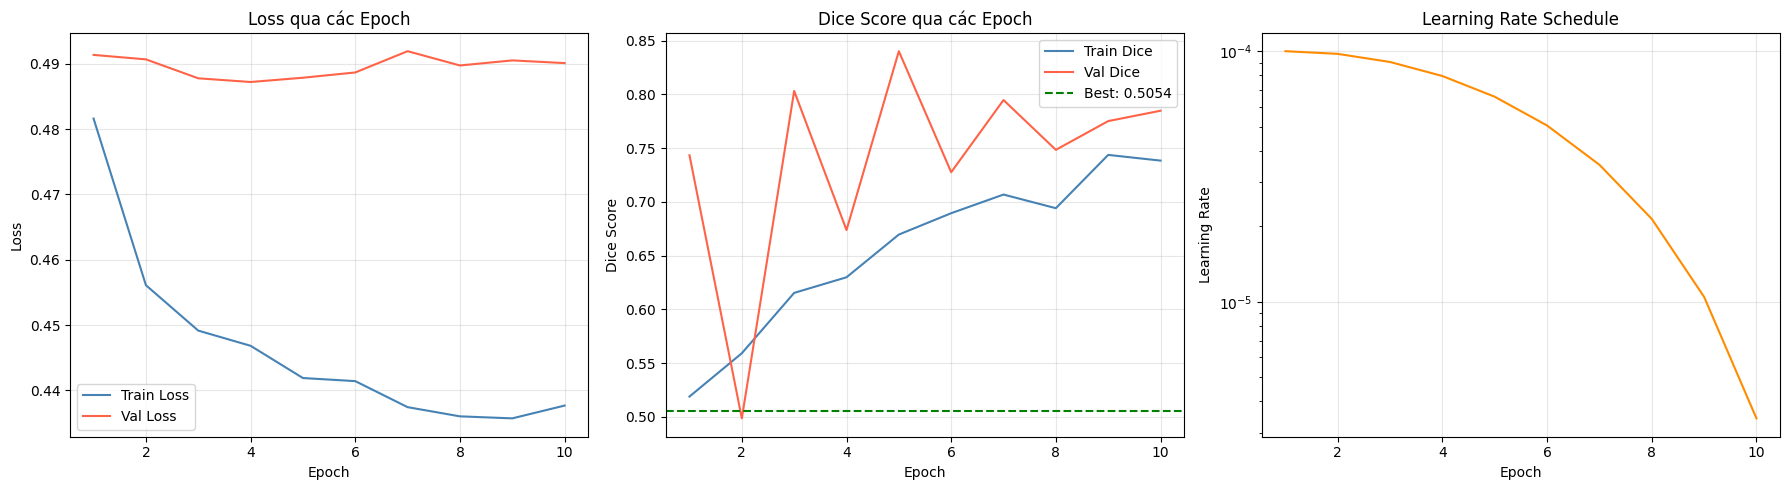

💾 Đã lưu biểu đồ: /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/model/checkpoints/mamba_unet_baseline_training_curves.png


In [ ]:
import matplotlib
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
epochs_range = range(1, len(history['train_loss']) + 1)

# Biểu đồ 1: Loss
axes[0].plot(epochs_range, history['train_loss'], label='Train Loss', color='steelblue')
axes[0].plot(epochs_range, history['val_loss'],   label='Val Loss',   color='tomato')
axes[0].set_title('Loss qua các Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Biểu đồ 2: Dice Score
axes[1].plot(epochs_range, history['train_dice'], label='Train Dice', color='steelblue')
axes[1].plot(epochs_range, history['val_dice'],   label='Val Dice',   color='tomato')
axes[1].axhline(y=early_stopping.best_score, color='green', linestyle='--', label=f'Best: {early_stopping.best_score:.4f}')
axes[1].set_title('Dice Score qua các Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Dice Score')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Biểu đồ 3: Learning Rate
axes[2].plot(epochs_range, history['lr'], color='darkorange')
axes[2].set_title('Learning Rate Schedule')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Learning Rate')
axes[2].set_yscale('log')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plot_path = Path(config['SAVE']['checkpoint_dir']) / f"{config['SAVE']['experiment_name']}_training_curves.png"
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'💾 Đã lưu biểu đồ: {plot_path}')

## Cell 11 — Đánh giá trên tập Test

In [ ]:
from src.utils import load_checkpoint

# Tải model tốt nhất đã lưu
best_ckpt = Path(config['SAVE']['checkpoint_dir']) / f"{config['SAVE']['experiment_name']}_best.pth"
if best_ckpt.exists():
    load_checkpoint(str(best_ckpt), model, device=DEVICE)
    print(f'✅ Đã tải model tốt nhất từ: {best_ckpt}')
else:
    print('⚠️  Không tìm thấy best.pth — dùng model hiện tại')

# Đánh giá trên tập Test
test_loss, test_metrics = validate(model, test_loader, criterion, DEVICE)

print('\n' + '='*50)
print('KẾT QUẢ TRÊN TẬP TEST')
print('='*50)
print(f'  Test Loss      : {test_loss:.4f}')
print(f'  Test Dice      : {test_metrics.get("dice", 0):.4f}')
print(f'  Test IoU       : {test_metrics.get("iou", 0):.4f}')
print(f'  Test Precision : {test_metrics.get("precision", 0):.4f}')
print(f'  Test Recall    : {test_metrics.get("recall", 0):.4f}')
print('='*50)

⚠️  Không tìm thấy best.pth — dùng model hiện tại


  [Val]  :   0%|          | 0/100 [00:00<?, ?it/s]


KẾT QUẢ TRÊN TẬP TEST
  Test Loss      : 0.4848
  Test Dice      : 0.7702
  Test IoU       : 0.7634
  Test Precision : 0.7947
  Test Recall    : 0.9619


## Cell 12 — Xem kết quả trực quan (Visualization)

In [ ]:
import numpy as np
from src.utils import plot_predictions

model.eval()
NUM_SAMPLES = 5  # Số ảnh muốn xem

# Lấy 1 batch từ test loader
test_imgs, test_masks = next(iter(test_loader))
test_imgs_gpu = test_imgs[:NUM_SAMPLES].to(DEVICE)

with torch.no_grad():
    test_preds = model(test_imgs_gpu).cpu().numpy()

test_imgs_np  = test_imgs[:NUM_SAMPLES].numpy()
test_masks_np = test_masks[:NUM_SAMPLES].numpy()

print(f'Hiển thị {NUM_SAMPLES} mẫu từ tập Test:\n')
for i in range(NUM_SAMPLES):
    dice_i = float(dice_score(
        torch.tensor(test_preds[i:i+1]),
        torch.tensor(test_masks_np[i:i+1])
    ))
    plot_predictions(
        image     = test_imgs_np[i],
        mask_true = test_masks_np[i],
        mask_pred = test_preds[i],
        title     = f'Mẫu #{i+1}  |  Dice = {dice_i:.4f}'
    )

## Cell 13 — Lưu Mô Hình (Thủ công / Tùy chọn)

Chạy cell này nếu bạn muốn chủ động lưu lại trọng số mô hình sau khi huấn luyện xong.
- **Dung lượng siêu nhẹ**: Chỉ lưu `model.state_dict()` (~80 MB) thay vì ~1 GB checkpoint đầy đủ, hoàn toàn không làm đầy ổ cứng hay tràn Google Drive.
- **Lựa chọn nơi lưu**: Mặc định lưu vào Google Drive (`model/checkpoints/`), hoặc có thể đổi sang lưu tạm trên Colab (`/content/`).


In [ ]:
import os
from pathlib import Path
import torch

# ============================================================
# 1. CHỌN NƠI LƯU TRỌNG SỐ MÔ HÌNH
# ============================================================
# Cách A (Mặc định): Lưu lên Google Drive (chỉ ~80 MB, rất nhẹ)
SAVE_DIR = MODEL_DIR / 'checkpoints'

# Cách B: Lưu tạm trên ổ cứng Colab (không đồng bộ về PC):
# SAVE_DIR = Path('/content/checkpoints')

SAVE_DIR.mkdir(parents=True, exist_ok=True)
exp_name = config['SAVE'].get('experiment_name', 'mamba_unet')
save_path = SAVE_DIR / f'{exp_name}_final_weights.pth'

# ============================================================
# 2. LƯU CHỈ TRỌNG SỐ (STATE_DICT) — SIÊU GỌN NHẸ
# ============================================================
torch.save(model.state_dict(), str(save_path))

# 3. Kiểm tra dung lượng file đã lưu
file_size_mb = os.path.getsize(save_path) / (1024 * 1024)
print('=' * 50)
print('🎉 ĐÃ LƯU MÔ HÌNH THÀNH CÔNG!')
print(f'📁 File lưu tại : {save_path}')
print(f'💾 Dung lượng   : {file_size_mb:.2f} MB (nhẹ, an toàn cho máy)')
print('=' * 50)


🎉 ĐÃ LƯU MÔ HÌNH THÀNH CÔNG!
📁 File lưu tại : /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/model/checkpoints/mamba_unet_baseline_final_weights.pth
💾 Dung lượng   : 145.90 MB (nhẹ, an toàn cho máy)
